# Recuperação e recall

Resultados reais carregados dos artefatos do projeto.

,metodo,particao,limiar,total,corretos_binarios,cobertura,recall1_macro,recall3_macro,hit1,hit3
17,tfidf_stem,calibracao,0.15,18,17,14,0.866667,1.0000,0.866667,1.0
24,tfidf_stem,final,0.15,14,12,8,0.812500,0.8125,1.000000,1.0


('bm25_stem', 'calibracao') recall@1= 0.8667 recall@3= 1.0 hit@3= 1.0
('bm25_stem', 'final') recall@1= 0.8125 recall@3= 0.8125 hit@3= 1.0
('tfidf_original', 'calibracao') recall@1= 0.7333 recall@3= 0.8 hit@3= 0.8
('tfidf_original', 'final') recall@1= 0.5625 recall@3= 0.5625 hit@3= 0.625
('tfidf_stem', 'calibracao') recall@1= 0.8667 recall@3= 1.0 hit@3= 1.0
('tfidf_stem', 'final') recall@1= 0.8125 recall@3= 0.8125 hit@3= 1.0


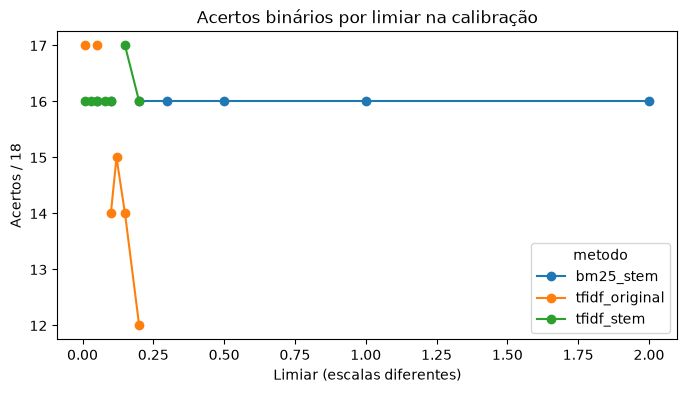

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root=Path.cwd()
pd.set_option('display.max_colwidth',100)
d=pd.read_csv(root/'avaliacao/resultados/v6/calibracao.csv')
display(d[(d.metodo=='tfidf_stem') & (d.limiar==0.15)])
r=pd.read_csv(root/'avaliacao/resultados/v6/recuperacao_metodos.csv')
for name,g in r[r.relevantes.notna()].groupby(['metodo','particao']):
 print(name, 'recall@1=',round(g.recall1.mean(),4),'recall@3=',round(g.recall3.mean(),4),'hit@3=',round(g.hit3.mean(),4))
d[d.particao=='calibracao'].pivot(index='limiar',columns='metodo',values='corretos_binarios').plot(marker='o', title='Acertos binários por limiar na calibração',xlabel='Limiar (escalas diferentes)',ylabel='Acertos / 18',figsize=(8,4));plt.show()
